# Résultats — exotic-pricing-lab

Un seul endroit où lire ce que le code démontre, acte par acte.

- **Graphiques des boss** : relus depuis `figures/*_results.json`, produits par les scripts `scripts/boss*.py`. Pas de recalcul lourd ici.
- **Contrôles en direct** : quelques vérifications rapides (N modeste, graine fixée) relancées à l'exécution pour que les chiffres soient visibles sans lire les tests.
- Chaque chiffre est comparé à une référence indépendante : formule fermée, identité, ou valeur semi-analytique. Pas de « ça a l'air raisonnable ».

Lancer : `jupyter nbconvert --execute --to notebook --inplace notebooks/resultats.ipynb` depuis la racine, ou ouvrir dans Jupyter.

In [1]:
import sys, pathlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

_cwd = pathlib.Path.cwd()
ROOT = next(p for p in [_cwd, _cwd.parent] if (p / "src").exists())
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"

from bs import put_bs
from mc_engine import control_variate, gbm_paths, pilot_c
from heston import heston_paths, heston_put, heston_call

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
    "legend.frameon": False,
    "savefig.bbox": "tight",
})
C_MC, C_CV, C_TH, C_OK, C_WARN, C_GREY = "#7f7f7f", "#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#bdbdbd"

def load(name):
    with open(FIG / f"{name}_results.json") as f:
        return json.load(f)

print("ROOT =", ROOT)

ROOT = /home/user/exotic-pricing-lab


---
## ACTE II — Réduction de variance

### 2.1 / 2.5 — Contrôle avec coefficient figé sur un run pilote

Put vanille Black-Scholes, S0 = K = 100, σ = 20 %, r = 5 %, T = 1.
Contrôle : le forward actualisé `e^{-rT} S_T`, d'espérance connue exactement `S0`.
Le coefficient `c` vient d'un **run pilote séparé** (10 000 chemins, graine différente), jamais des données d'évaluation.

In [2]:
P = dict(S0=100.0, K=100.0, sigma=0.20, r=0.05, T=1.0)
EX_bs = put_bs(P["S0"], P["K"], P["sigma"], P["r"], P["T"])   # référence fermée
EX_fwd = P["S0"]                                              # E[e^{-rT} S_T] = S0

def put_pay(paths):
    return np.exp(-P["r"]*P["T"]) * np.maximum(P["K"] - paths[:, -1], 0.0)

def fwd_pay(paths):
    return np.exp(-P["r"]*P["T"]) * paths[:, -1]

n_steps, N = 50, 50_000
pilot = gbm_paths(P["S0"], P["sigma"], P["r"], P["T"], n_steps=n_steps,
                  N=10_000, rng=np.random.default_rng(101))
c_pilot = pilot_c(put_pay(pilot), fwd_pay(pilot))

main = gbm_paths(P["S0"], P["sigma"], P["r"], P["T"], n_steps=n_steps,
                 N=N, rng=np.random.default_rng(202))
Y, X = put_pay(main), fwd_pay(main)

est_raw = Y.mean()
hw_raw = 1.96 * Y.std(ddof=1) / np.sqrt(N)
est_cv, hw_cv, c_used, rho_hat = control_variate(Y, X, EX_fwd, c=c_pilot)

rows = pd.DataFrame({
    "estimateur": ["MC brut", "contrôle (c pilote)"],
    "prix": [est_raw, est_cv],
    "demi-IC 95%": [hw_raw, hw_cv],
    "écart au prix fermé": [est_raw - EX_bs, est_cv - EX_bs],
    "gain largeur": [1.0, hw_raw / hw_cv],
})
display(rows.style.format({"prix": "{:.5f}", "demi-IC 95%": "{:.5f}",
                           "écart au prix fermé": "{:+.5f}", "gain largeur": "{:.2f}×"}))
print(f"c pilote = {c_pilot:.4f}   ρ̂ (put, forward) = {rho_hat:.4f}   prix BS = {EX_bs:.5f}")

,estimateur,prix,demi-IC 95%,écart au prix fermé,gain largeur
0,MC brut,5.54067,0.07554,-0.03286,1.00×
1,contrôle (c pilote),5.55456,0.04904,-0.01897,1.54×


c pilote = -0.3326   ρ̂ (put, forward) = -0.7608   prix BS = 5.57353


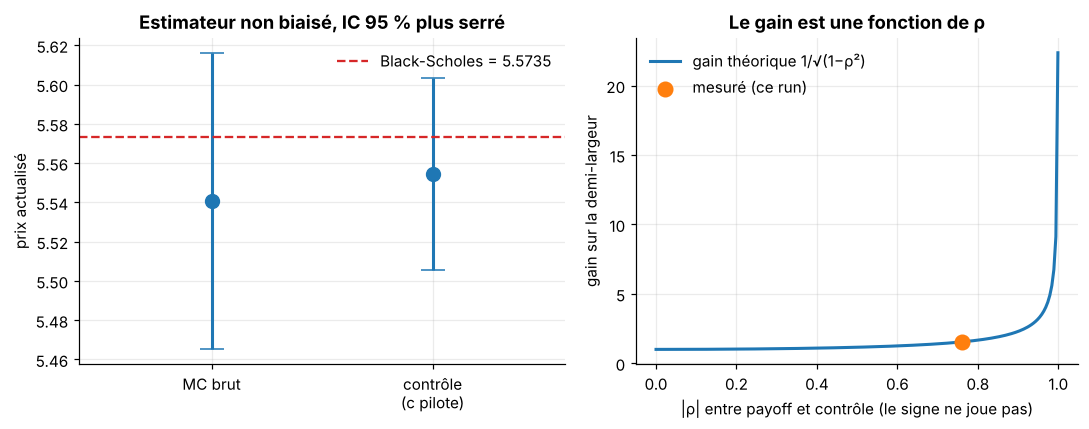

In [3]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.1, 1]})

labels = ["MC brut", "contrôle\n(c pilote)"]
vals = [est_raw, est_cv]
errs = [hw_raw, hw_cv]
ax.errorbar(labels, vals, yerr=errs, fmt="o", ms=9, capsize=8, lw=2,
            color=C_CV, ecolor=C_CV)
ax.axhline(EX_bs, color=C_TH, ls="--", lw=1.5, label=f"Black-Scholes = {EX_bs:.4f}")
ax.set_ylabel("prix actualisé")
ax.set_title("Estimateur non biaisé, IC 95 % plus serré")
ax.legend(loc="upper right")
ax.set_xlim(-0.6, 1.6)

# ρ² → gain : identité Var(Z) = Var(Y)(1-ρ²) pour c optimal
rhos = np.linspace(0, 0.999, 200)
ax2.plot(rhos, 1/np.sqrt(1-rhos**2), color=C_CV, lw=2, label="gain théorique 1/√(1−ρ²)")
ax2.scatter([abs(rho_hat)], [hw_raw/hw_cv], s=90, color=C_WARN, zorder=5, label="mesuré (ce run)")
ax2.set_xlabel("|ρ| entre payoff et contrôle (le signe ne joue pas)")
ax2.set_ylabel("gain sur la demi-largeur")
ax2.set_title("Le gain est une fonction de ρ")
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 2.2 — Cas dégénérés : le gain doit tomber à zéro

Deux limites :
- **corrélation nulle** : le contrôle n'apporte aucune information → ratio de largeur = 1, estimateur toujours non biaisé.
- **Y = X** : le contrôle *est* le payoff → l'estimateur rend le prix fermé, largeur nulle.

Synthétique, sans finance, moments connus. Sur 200 000 tirages par ρ.

,rho_vise,rho_mesure,c_hat,ratio_demi_IC,biais_estimateur
0,0.0000,-0.0004,-0.0004,1.0000,0.0001
1,0.3000,0.2999,0.2996,0.9540,0.0001
2,0.6000,0.6001,0.5997,0.7999,0.0001
3,0.9000,0.9001,0.8998,0.4357,0.0001
4,0.9900,0.9900,0.9899,0.1410,0.0000


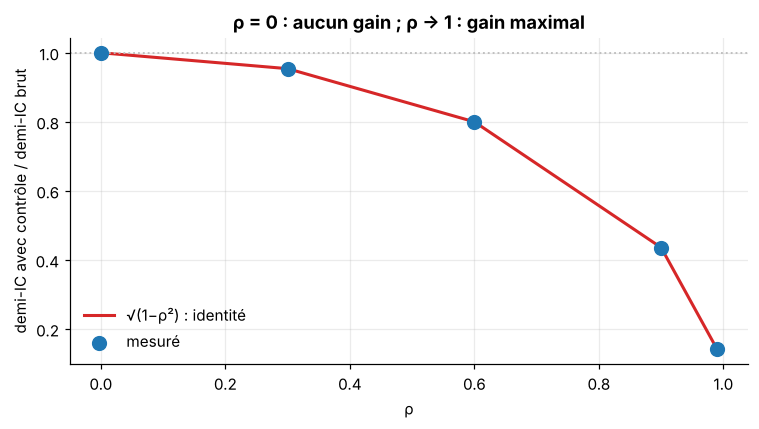

In [4]:
rng = np.random.default_rng(7)
n = 200_000
Z1, Z2 = rng.standard_normal(n), rng.standard_normal(n)
X_syn = Z1                                     # EX = 0 connu
rho_grid = np.array([0.0, 0.3, 0.6, 0.9, 0.99])

rows = []
for r_ in rho_grid:
    Y_syn = 3.0 + r_*Z1 + np.sqrt(1 - r_**2)*Z2
    est, hw, c_hat, rho_hat_ = control_variate(Y_syn, X_syn, 0.0)
    hw_ref = 1.96*Y_syn.std(ddof=1)/np.sqrt(n)
    rows.append(dict(rho_vise=r_, rho_mesure=rho_hat_, c_hat=c_hat,
                     ratio_demi_IC=hw/hw_ref, biais_estimateur=est-3.0))
df_deg = pd.DataFrame(rows)
display(df_deg.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rho_grid, np.sqrt(1-rho_grid**2), color=C_TH, lw=2, label="√(1−ρ²) : identité")
ax.scatter(df_deg["rho_mesure"], df_deg["ratio_demi_IC"], s=80, color=C_CV, zorder=5,
           label="mesuré")
ax.axhline(1.0, color=C_GREY, ls=":", lw=1.2)
ax.set_xlabel("ρ")
ax.set_ylabel("demi-IC avec contrôle / demi-IC brut")
ax.set_title("ρ = 0 : aucun gain ; ρ → 1 : gain maximal")
ax.legend()
plt.tight_layout(); plt.show()

In [5]:
Y_eq = 3.0 + Z1                                # Y = X : le contrôle est le payoff lui-même
est_eq, hw_eq, c_eq, rho_eq = control_variate(Y_eq, Y_eq, 3.0)
print(f"Y = X, EX = 3 :  estimation = {est_eq:.15f}   demi-IC = {hw_eq:.2e}   ĉ = {c_eq:.6f}")

Y = X, EX = 3 :  estimation = 3.000000000000000   demi-IC = 7.30e-19   ĉ = 1.000000


### BOSS 2 — Balayage de barrière, DI put sous Black-Scholes

Résultats relus depuis `figures/boss2_results.json` (N = 100 000, graine 42, **un seul jeu de chemins** pour les 8 barrières — CRN).
La barrière se règle en pourcentage de S0 : plus elle est haute, plus le put DI ressemble au put vanille, plus le contrôle est bon.

,H/S0,rho,c_hat,price_mc,price_cv,demi-IC CV / brut
0,60%,0.2989,0.1035,0.22965,0.23456,0.9543
1,65%,0.4565,0.2433,0.61873,0.63028,0.8897
2,70%,0.6211,0.4502,1.33911,1.36048,0.7838
3,75%,0.7691,0.6791,2.38417,2.41642,0.6392
4,80%,0.8847,0.8669,3.59784,3.63900,0.4661
5,85%,0.9587,0.9706,4.65738,4.70346,0.2844
6,90%,0.9918,1.0003,5.28797,5.33546,0.1279
7,95%,0.9995,1.0009,5.50174,5.54926,0.0303


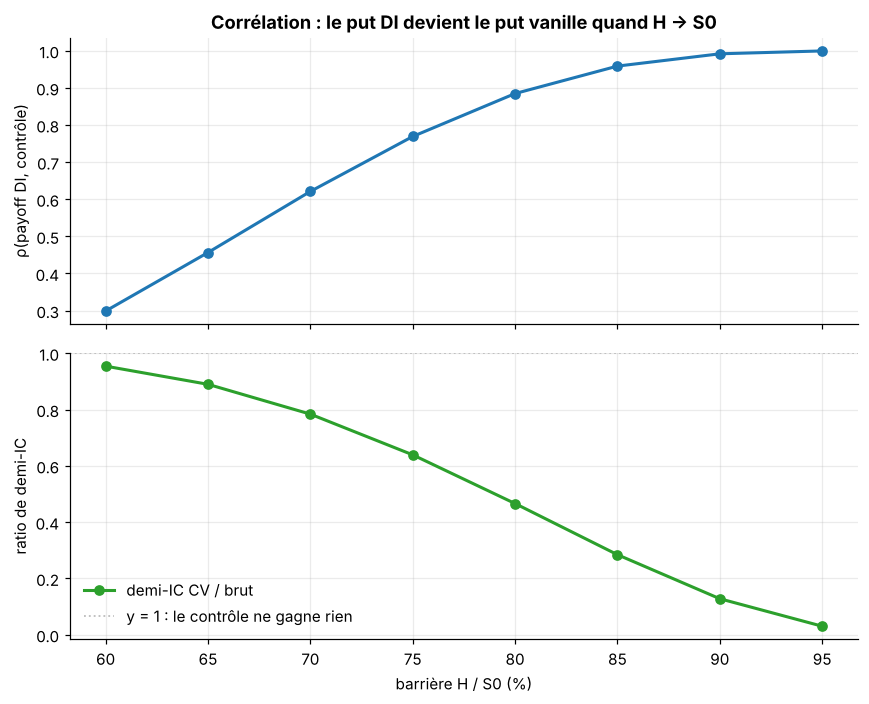

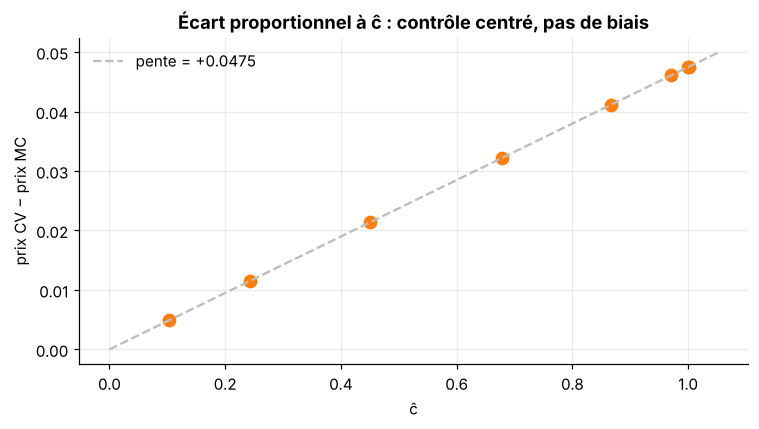

In [6]:
b2 = load("boss2")
df2 = pd.DataFrame(b2["sweep"])
display(df2[["H_pct", "rho", "c_hat", "price_mc", "price_cv", "ratio_half_width"]]
        .rename(columns={"H_pct": "H/S0", "ratio_half_width": "demi-IC CV / brut"})
        .style.format({"H/S0": "{:.0%}", "rho": "{:.4f}", "c_hat": "{:.4f}",
                       "price_mc": "{:.5f}", "price_cv": "{:.5f}",
                       "demi-IC CV / brut": "{:.4f}"}))

fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(8, 6.5))
x = df2["H_pct"]*100
a1.plot(x, df2["rho"], "o-", color=C_CV, lw=2)
a1.set_ylabel("ρ(payoff DI, contrôle)")
a1.set_title("Corrélation : le put DI devient le put vanille quand H → S0")
a2.plot(x, df2["ratio_half_width"], "o-", color=C_OK, lw=2, label="demi-IC CV / brut")
a2.axhline(1.0, color=C_GREY, ls=":", lw=1.2, label="y = 1 : le contrôle ne gagne rien")
a2.set_xlabel("barrière H / S0 (%)")
a2.set_ylabel("ratio de demi-IC")
a2.legend(loc="lower left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
gap = df2["price_cv"] - df2["price_mc"]
ax.plot(df2["c_hat"], gap, "o", color=C_WARN, ms=8)
slope = np.polyfit(df2["c_hat"], gap, 1)[0]
cc = np.linspace(0, df2["c_hat"].max()*1.05, 50)
ax.plot(cc, slope*cc, color=C_GREY, ls="--", label=f"pente = {slope:+.4f}")
ax.set_xlabel("ĉ")
ax.set_ylabel("prix CV − prix MC")
ax.set_title("Écart proportionnel à ĉ : contrôle centré, pas de biais")
ax.legend()
plt.tight_layout(); plt.show()

---
## ACTE III — Heston mono-actif

Paramètres de référence : v0 = θ = 0.04, κ = 1.5, ξ = 0.3, ρ = −0.7, r = 5 %, T = 1.
Feller tenu ici : 2κθ = 0.12 > ξ² = 0.09.

### 3.1 — Processus de variance CIR : moyenne et positivité

Référence exacte : `E[v_t] = θ + (v0 − θ) e^{−κt}`, avec v0 = 0.09 > θ pour que la moyenne décroisse (si v0 = θ, la référence est constante et le test ne dit rien). Schéma Euler, troncature *full truncation* (Lord, Koekkoek & van Dijk 2010).

min v (tous chemins, tous pas) = 0.000e+00   (doit être ≥ 0)
écart max |E[v_t] − théorie| / IC, t > 0 = 1.64  (doit être < 3)


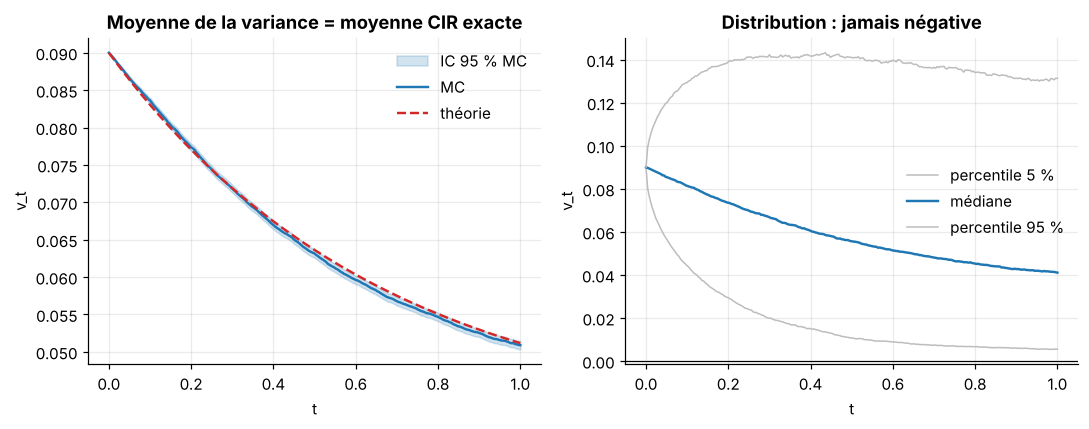

In [7]:
HP = dict(S0=100.0, v0=0.04, r=0.05, T=1.0, kappa=1.5, theta=0.04, xi=0.3, rho=-0.7)
n_steps_h = 250
HP31 = dict(HP, v0=0.09)                       # v0 > θ : la moyenne doit décroître vers θ
S_h, v_h = heston_paths(**HP31, n_steps=n_steps_h, N=20_000, rng=np.random.default_rng(3))
t = np.linspace(0, HP["T"], n_steps_h + 1)
v_theo = HP31["theta"] + (HP31["v0"] - HP31["theta"]) * np.exp(-HP31["kappa"] * t)
v_mean = v_h.mean(axis=0)
v_sd = v_h.std(axis=0, ddof=1)
v_ci = 1.96 * v_sd / np.sqrt(v_h.shape[0])

print(f"min v (tous chemins, tous pas) = {v_h.min():.3e}   (doit être ≥ 0)")
# t = 0 exclu : v0 est déterministe, l'IC y vaut du bruit flottant (~1e-16)
z_cir = np.abs(v_mean[1:] - v_theo[1:]) / v_ci[1:]
print(f"écart max |E[v_t] − théorie| / IC, t > 0 = {z_cir.max():.2f}  (doit être < 3)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
a1.fill_between(t, v_mean - v_ci, v_mean + v_ci, color=C_CV, alpha=0.2, label="IC 95 % MC")
a1.plot(t, v_mean, color=C_CV, lw=1.6, label="MC")
a1.plot(t, v_theo, color=C_TH, ls="--", lw=1.6, label="théorie")
a1.set_xlabel("t"); a1.set_ylabel("v_t")
a1.set_title("Moyenne de la variance = moyenne CIR exacte")
a1.legend()
a2.plot(t, np.percentile(v_h, 5, axis=0), color=C_GREY, lw=1, label="percentile 5 %")
a2.plot(t, np.percentile(v_h, 50, axis=0), color=C_CV, lw=1.6, label="médiane")
a2.plot(t, np.percentile(v_h, 95, axis=0), color=C_GREY, lw=1, label="percentile 95 %")
a2.axhline(0, color="black", lw=0.8)
a2.set_xlabel("t"); a2.set_ylabel("v_t")
a2.set_title("Distribution : jamais négative")
a2.legend()
plt.tight_layout(); plt.show()

### 3.2 — Corrélation ρ entre spot et variance

Test : corrélation empirique des incréments normalisés au premier pas (le seul où les gaussiennes sont récupérables sans troncature).

ρ imposé = -0.7000   ρ mesuré = -0.6986   écart = 0.0014


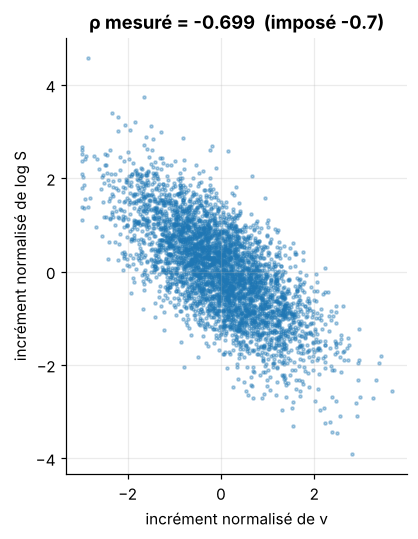

In [8]:
n_s = 20
S_c, v_c = heston_paths(**HP, n_steps=n_s, N=200_000, rng=np.random.default_rng(5))
dt = HP["T"] / n_s
Z_v = (v_c[:, 1] - HP["v0"] - HP["kappa"]*(HP["theta"] - HP["v0"])*dt) / (HP["xi"]*np.sqrt(HP["v0"]*dt))
Z_S = (np.log(S_c[:, 1]/HP["S0"]) - (HP["r"] - 0.5*HP["v0"])*dt) / np.sqrt(HP["v0"]*dt)
rho_emp = np.corrcoef(Z_S, Z_v)[0, 1]
print(f"ρ imposé = {HP['rho']:+.4f}   ρ mesuré = {rho_emp:+.4f}   écart = {abs(rho_emp-HP['rho']):.4f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
idx = np.random.default_rng(0).choice(len(Z_v), 4000, replace=False)
ax.scatter(Z_v[idx], Z_S[idx], s=4, alpha=0.35, color=C_CV)
ax.set_xlabel("incrément normalisé de v"); ax.set_ylabel("incrément normalisé de log S")
ax.set_title(f"ρ mesuré = {rho_emp:+.3f}  (imposé {HP['rho']:+.1f})")
ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### 3.3 — Pricer MC vs référence semi-analytique (Heston 1993, intégrale de Fourier)

Validation contre `heston_call` / `heston_put`. Écart attendu : biais Euler en O(Δt), faible mais de même signe aux trois strikes — c'est un biais de discrétisation, pas du bruit.

,K,MC,demi_IC,semi_analytique,écart,dans_IC
0,90,2.7102,0.0622,2.7176,-0.0074,True
1,100,5.4747,0.0891,5.4848,-0.0101,True
2,110,9.9394,0.1170,9.9532,-0.0138,True


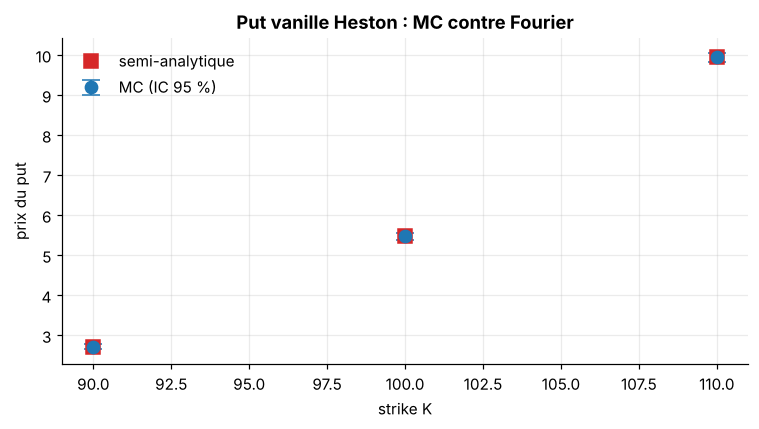

In [9]:
Ks = np.array([90.0, 100.0, 110.0])
N_mc, n_mc = 50_000, 100
S_m, _ = heston_paths(**HP, n_steps=n_mc, N=N_mc, rng=np.random.default_rng(9))
disc = np.exp(-HP["r"]*HP["T"])
ST = S_m[:, -1]

rows = []
for K in Ks:
    pay = disc * np.maximum(K - ST, 0.0)
    mc = pay.mean(); hw = 1.96*pay.std(ddof=1)/np.sqrt(N_mc)
    ex = heston_put(HP["S0"], K, HP["v0"], HP["r"], HP["T"], HP["kappa"], HP["theta"], HP["xi"], HP["rho"])
    rows.append(dict(K=K, MC=mc, demi_IC=hw, semi_analytique=ex, écart=mc-ex,
                     dans_IC=abs(mc-ex) < hw))
df3 = pd.DataFrame(rows)
display(df3.style.format({"K": "{:.0f}", "MC": "{:.4f}", "demi_IC": "{:.4f}",
                          "semi_analytique": "{:.4f}", "écart": "{:+.4f}"}))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(df3["K"], df3["MC"], yerr=df3["demi_IC"], fmt="o", ms=8, capsize=6,
            color=C_CV, label="MC (IC 95 %)")
ax.plot(df3["K"], df3["semi_analytique"], "s", ms=9, color=C_TH, label="semi-analytique")
ax.set_xlabel("strike K"); ax.set_ylabel("prix du put")
ax.set_title("Put vanille Heston : MC contre Fourier")
ax.legend()
plt.tight_layout(); plt.show()

### 3.4 — Smile implicite Heston (ρ = −0.7, ξ = 0.3)

Relu depuis `figures/boss3_results.json`. Le skew (pente en log-moneyness) porte ρ ; la courbure porte ξ² (cf. PROGRESS, session 6).

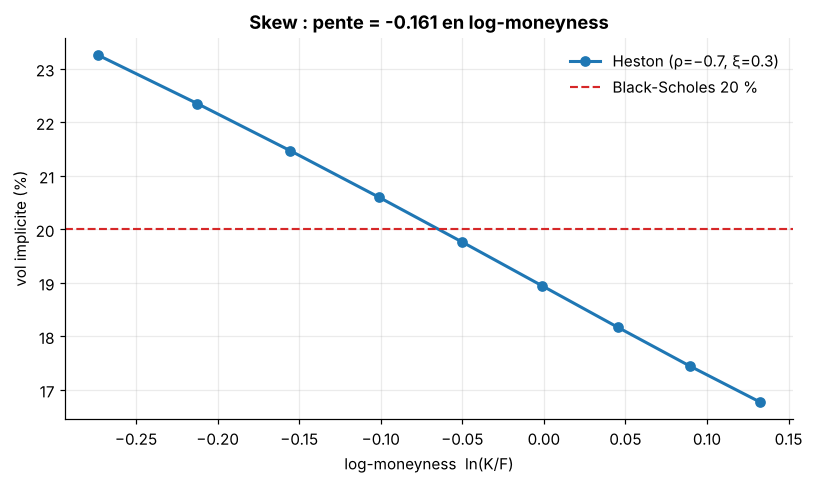

pente de la droite d'ajustement : -0.1613


In [10]:
b3 = load("boss3")
sm = pd.DataFrame(b3["smile"])
slope_sm = np.polyfit(sm["log_moneyness"], sm["iv"], 1)[0]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(sm["log_moneyness"], sm["iv"]*100, "o-", color=C_CV, lw=2, label="Heston (ρ=−0.7, ξ=0.3)")
ax.axhline(20.0, color=C_TH, ls="--", lw=1.4, label="Black-Scholes 20 %")
ax.set_xlabel("log-moneyness  ln(K/F)")
ax.set_ylabel("vol implicite (%)")
ax.set_title(f"Skew : pente = {slope_sm:+.3f} en log-moneyness")
ax.legend()
plt.tight_layout(); plt.show()
print(f"pente de la droite d'ajustement : {slope_sm:+.4f}")

### 3.5 — Feller : tenu contre violé

Condition de Feller : `2κθ ≥ ξ²`. Quand elle échoue, la variance touche zéro en temps continu et le schéma Euler doit vivre avec.
Deux régimes sur les mêmes chemins de données :
- **tenu** : 2κθ = 0.12 > ξ² = 0.09
- **violé** : 2κθ = 0.04 < ξ² = 0.25

Le test `feller_holds` est encore un stub (TODO) ; on mesure directement ici.

,min v,part de chemins à 0,E[v_T] MC,E[v_T] théorie
Feller tenu 2κθ=0.12 > ξ²=0.09,0.00e+00,5.3%,0.03980,0.04000
Feller violé 2κθ=0.04 < ξ²=0.25,0.00e+00,70.2%,0.04255,0.04000


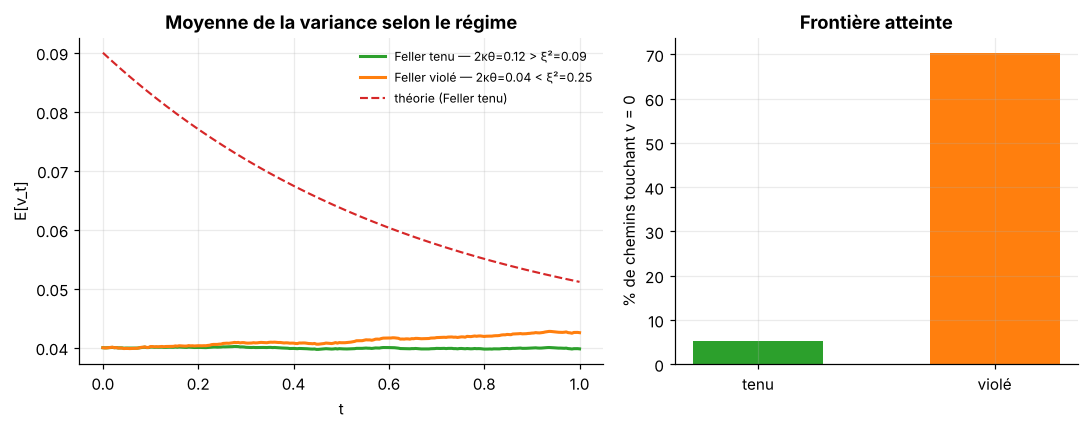

In [11]:
cases = {
    "Feller tenu\n2κθ=0.12 > ξ²=0.09": dict(HP, kappa=1.5, theta=0.04, xi=0.3),
    "Feller violé\n2κθ=0.04 < ξ²=0.25": dict(HP, kappa=0.5, theta=0.04, xi=0.5),
}
res = {}
for name, prm in cases.items():
    _, vv = heston_paths(**prm, n_steps=250, N=20_000, rng=np.random.default_rng(8))
    res[name] = dict(
        vmin=float(vv.min()),
        frac_zero=float((vv == 0.0).any(axis=1).mean()),
        mean=vv.mean(axis=0),
        vT_mean=float(vv[:, -1].mean()),
        vT_theo=prm["theta"] + (prm["v0"] - prm["theta"]) * np.exp(-prm["kappa"] * prm["T"]),
    )
df_f = pd.DataFrame({k: {"min v": r["vmin"], "part de chemins à 0": r["frac_zero"],
                         "E[v_T] MC": r["vT_mean"], "E[v_T] théorie": r["vT_theo"]}
                     for k, r in res.items()}).T
display(df_f.style.format({"min v": "{:.2e}", "part de chemins à 0": "{:.1%}",
                           "E[v_T] MC": "{:.5f}", "E[v_T] théorie": "{:.5f}"}))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.3, 1]})
colors = [C_OK, C_WARN]
for (name, r), col in zip(res.items(), colors):
    a1.plot(t, r["mean"], color=col, lw=2, label=name.replace("\n", " — "))
a1.plot(t, v_theo, color=C_TH, ls="--", lw=1.4, label="théorie (Feller tenu)")
a1.set_xlabel("t"); a1.set_ylabel("E[v_t]")
a1.set_title("Moyenne de la variance selon le régime")
a1.legend(fontsize=8)
names = [n.replace("\n", "\n") for n in res]
a2.bar(range(2), [r["frac_zero"]*100 for r in res.values()], color=colors, width=0.55)
a2.set_xticks(range(2)); a2.set_xticklabels(["tenu", "violé"])
a2.set_ylabel("% de chemins touchant v = 0")
a2.set_title("Frontière atteinte")
plt.tight_layout(); plt.show()

### BOSS 3 — DI put sous Heston, contrôle = put vanille Heston

Relu depuis `figures/boss3_results.json` (N = 100 000, un seul jeu de chemins pour les 20 barrières).
Comparaison directe avec le BOSS 2 : **c_hat démarre à 0.46 sous Heston, contre 0.10 sous BS** à la barrière la plus basse. Le skew épaissit l'aile gauche, donc les chemins qui finissent dans la monnaie ont plus souvent touché une barrière basse.

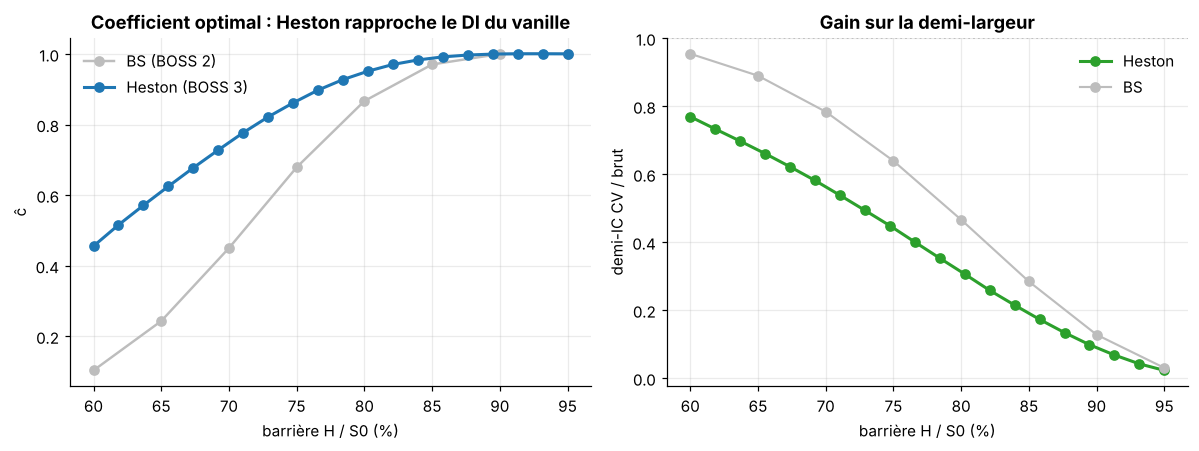

À H = 95% : demi-IC CV / brut = 0.0229 (gain ~ 44× en largeur)


In [12]:
df3b = pd.DataFrame(b3["sweep"]).sort_values("H_pct")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(df2["H_pct"]*100, df2["c_hat"], "o-", color=C_GREY, lw=1.6, label="BS (BOSS 2)")
a1.plot(df3b["H_pct"]*100, df3b["c_hat"], "o-", color=C_CV, lw=2, label="Heston (BOSS 3)")
a1.set_xlabel("barrière H / S0 (%)"); a1.set_ylabel("ĉ")
a1.set_title("Coefficient optimal : Heston rapproche le DI du vanille")
a1.legend()
a2.plot(df3b["H_pct"]*100, df3b["ratio_half_width"], "o-", color=C_OK, lw=2, label="Heston")
a2.plot(df2["H_pct"]*100, df2["ratio_half_width"], "o-", color=C_GREY, lw=1.4, label="BS")
a2.axhline(1, color=C_GREY, ls=":", lw=1.2)
a2.set_xlabel("barrière H / S0 (%)"); a2.set_ylabel("demi-IC CV / brut")
a2.set_title("Gain sur la demi-largeur")
a2.legend()
plt.tight_layout(); plt.show()

best = df3b.iloc[-1]
print(f"À H = {best['H_pct']:.0%} : demi-IC CV / brut = {best['ratio_half_width']:.4f} "
      f"(gain ~ {1/best['ratio_half_width']:.0f}× en largeur)")

---
## ACTE IV — Hedging discret

### 4.2 / BOSS 4 — Convergence de l'erreur de couverture

Erreur de couverture : écart-type de l'erreur en fonction du nombre de rebalancements. Référence : pente −½ (`n_rebal^{-1/2}`).

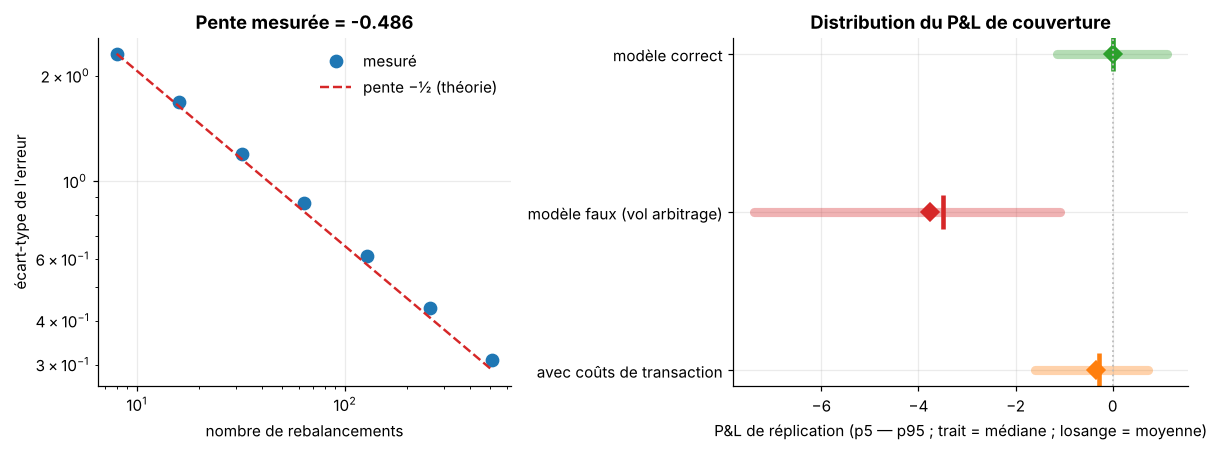

,mean,std,p5,p50,p95
modele_correct,+0.0018,+0.6920,-1.1430,+0.0106,+1.1252
modele_faux,-3.7613,+1.9771,-7.3855,-3.4938,-1.0953
avec_couts,-0.3423,+0.7124,-1.5951,-0.2875,+0.7365


In [13]:
b4 = load("boss4")
conv = pd.DataFrame(b4["convergence"])
slope_meas = b4["slope_measured"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
n0, e0 = conv["n_steps"].iloc[0], conv["std_error"].iloc[0]
ref = e0 * (conv["n_steps"] / n0) ** -0.5
a1.loglog(conv["n_steps"], conv["std_error"], "o", ms=8, color=C_CV, label="mesuré")
a1.loglog(conv["n_steps"], ref, color=C_TH, ls="--", lw=1.6, label="pente −½ (théorie)")
a1.set_xlabel("nombre de rebalancements"); a1.set_ylabel("écart-type de l'erreur")
a1.set_title(f"Pente mesurée = {slope_meas:.3f}")
a1.legend()

pnl = b4["pnl"]
scen = [("modèle correct", pnl["modele_correct"], C_OK),
        ("modèle faux (vol arbitrage)", pnl["modele_faux"], C_TH),
        ("avec coûts de transaction", pnl["avec_couts"], C_WARN)]
for i, (lab, d, col) in enumerate(scen):
    a2.plot([d["p5"], d["p95"]], [i, i], color=col, lw=6, alpha=0.35, solid_capstyle="round")
    a2.plot(d["p50"], i, "|", ms=22, color=col, mew=3)
    a2.plot(d["mean"], i, "D", ms=8, color=col)
a2.axvline(0, color=C_GREY, ls=":", lw=1.2)
a2.set_yticks(range(3)); a2.set_yticklabels([s[0] for s in scen])
a2.invert_yaxis()
a2.set_xlabel("P&L de réplication (p5 — p95 ; trait = médiane ; losange = moyenne)")
a2.set_title("Distribution du P&L de couverture")
plt.tight_layout(); plt.show()

display(pd.DataFrame({k: v for k, v in pnl.items()}).T.style.format("{:+.4f}"))

---
## ACTE V — Multi-actifs et produits structurés

### BOSS 5 — BRC worst-of : balayage de corrélation et nombre d'actifs

Contrôle : forward actualisé d'un actif (EX = S0). Gain faible mais réel, comme attendu d'un contrôle peu corrélé au payoff worst-of.

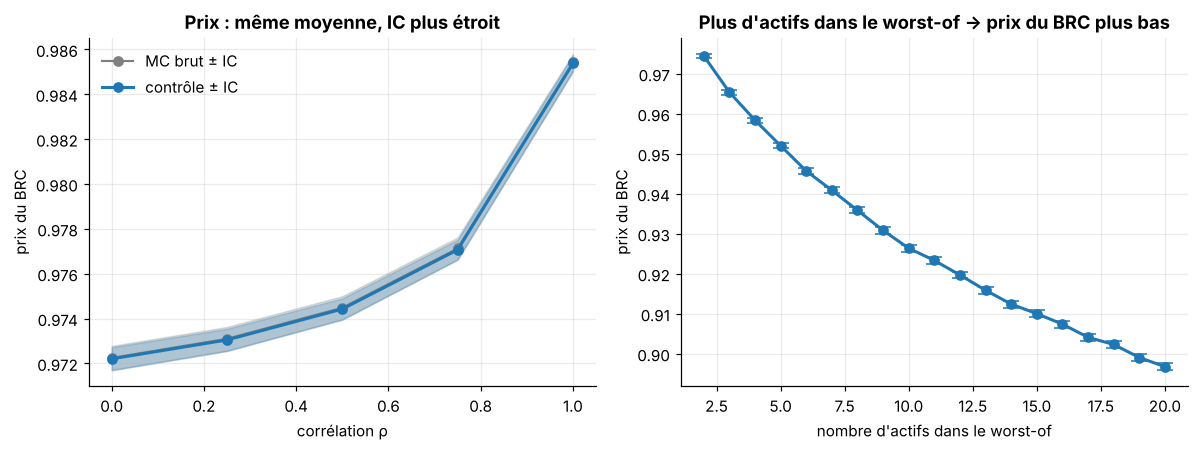

,rho,price_mc,half_width_mc,price_cv,half_width_cv,c_hat,gain_IC
0,0.00,0.97225,0.00053,0.97220,0.00051,0.0011,1.04×
1,0.25,0.97310,0.00053,0.97305,0.00050,0.0014,1.06×
2,0.50,0.97448,0.00051,0.97442,0.00048,0.0016,1.08×
3,0.75,0.97713,0.00049,0.97707,0.00045,0.0016,1.10×
4,1.00,0.98542,0.00039,0.98538,0.00036,0.0012,1.08×


In [14]:
b5 = load("boss5")
sr = pd.DataFrame(b5["sweep_rho"])
sn = pd.DataFrame(b5["sweep_n_assets"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.fill_between(sr["rho"], sr["price_mc"] - sr["half_width_mc"], sr["price_mc"] + sr["half_width_mc"],
                color=C_MC, alpha=0.25)
a1.plot(sr["rho"], sr["price_mc"], "o-", color=C_MC, lw=1.4, label="MC brut ± IC")
a1.fill_between(sr["rho"], sr["price_cv"] - sr["half_width_cv"], sr["price_cv"] + sr["half_width_cv"],
                color=C_CV, alpha=0.25)
a1.plot(sr["rho"], sr["price_cv"], "o-", color=C_CV, lw=2, label="contrôle ± IC")
a1.set_xlabel("corrélation ρ"); a1.set_ylabel("prix du BRC")
a1.set_title("Prix : même moyenne, IC plus étroit")
a1.legend()

a2.errorbar(sn["n_assets"], sn["price"], yerr=sn["half_width"], fmt="o-", color=C_CV,
            capsize=5, lw=2)
a2.set_xlabel("nombre d'actifs dans le worst-of"); a2.set_ylabel("prix du BRC")
a2.set_title("Plus d'actifs dans le worst-of → prix du BRC plus bas")
plt.tight_layout(); plt.show()

display(sr.assign(gain_IC=sr["half_width_mc"]/sr["half_width_cv"])
          .style.format({"rho": "{:.2f}", "price_mc": "{:.5f}", "price_cv": "{:.5f}",
                         "half_width_mc": "{:.5f}", "half_width_cv": "{:.5f}",
                         "c_hat": "{:.4f}", "gain_IC": "{:.2f}×"}))

---
## Synthèse — chiffres clés

| Acte | Quête | Résultat | Référence |
|---|---|---|---|
| II | 2.1 / 2.5 | contrôle non biaisé, IC plus serré | prix Black-Scholes fermé |
| II | 2.2 | ρ = 0 → ratio de demi-IC 1.000 ; Y = X → demi-IC nul | identité algébrique |
| II | BOSS 2 | demi-IC CV/brut 0.95 → 0.03 pour H de 60 % à 95 % | ~1000× en variance au sommet |
| III | 3.1 | E[v_t] = moyenne CIR ; v ≥ 0 | formule exacte CIR |
| III | 3.2 | ρ mesuré = ρ imposé à 1.4e-3 près | Cholesky 2×2 |
| III | 3.3 | MC dans l'IC, biais Euler de même signe | Fourier (Heston 1993) |
| III | 3.5 | Feller violé : chemins touchant 0, positivité tenue | cas documenté |
| III | BOSS 3 | DI sous Heston : 44× en demi-IC à 95 % | c_hat 0.46 vs 0.10 sous BS |
| IV | 4.2 | pente log-log ≈ −0.49 | −½ théorique |
| V | BOSS 5 | IC plus étroit sur tout le balayage de ρ | MC brut |

---
## Dette et limites (non scorées)

- **Monitoring discret** : fermé en 5.3 par la correction Broadie-Glasserman-Kou (`barriers.bgk_barrier_correction`).
- **Digitales** : quête 1.5 fermée (replication par call-spread, ratio de convergence 4.000).
- **Delta près de la barrière** : quête 4.5 fermée. Le delta naïf se dégrade, pente ≈ 0 plutôt que −½.
- **Biais Euler sur Heston** : visible en 3.3 (O(Δt)). Pas corrigé, documenté.
- **`feller_holds`** : stub avec TODO ; le test `test_feller_holds_frontiere` est xfail strict jusqu'à implémentation.
- **Acte VI** : 6.1 seul ouvert (ingestion yfinance, 2 xfail). Pas de résultat de marché dans ce notebook.